In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../Presuntos_Homicidios._Colombia,_2015_a_2024._Cifras_definitivas_20260916.csv")
print(f"Dataset: {len(df):,} filas × {df.shape[1]} columnas")
print(f"Períodos: {sorted(df['Año del hecho'].dropna().unique())}")
df.head(3)

Dataset: 125,284 filas × 33 columnas
Períodos: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


,ID,Año del hecho,Grupo de edad quinquenal,Grupo Mayor Menor de Edad,Grupo de Edad judicial,Ciclo Vital,Sexo de la victima,Estado Civil,País de Nacimiento,Escolaridad,...,Manera de muerte,Mecanismo Causal de la Lesión Fatal,Diagnostico Topográfico de la Lesión Fatal,Presunto Agresor Detallado,Localidad del Hecho,Ancestro Racial,Pueblo Indígena,Orientación Sexual,Identidad de Género,Transgénero
0,1,2015,(20 a 24),b) Mayor de Edad (>18 Años),(20 a 24),(18 a 28) Juventud,Hombre,Soltero(a),Colombia,Básica primaria,...,1 Presuntos Homicidios,Corto punzante,Trauma de abdomen,Sin información,Sin información,Mestizo,No había sido implementada,No había sido implementada,No había sido implementada,No había sido implementada
1,2,2015,(25 a 29),b) Mayor de Edad (>18 Años),(25 a 28),(18 a 28) Juventud,Hombre,Soltero(a),Colombia,Básica primaria,...,1 Presuntos Homicidios,Proyectil de arma de fuego,Trauma craneano,Sin información,Sin información,Mestizo,No había sido implementada,No había sido implementada,No había sido implementada,No había sido implementada
2,3,2015,(20 a 24),b) Mayor de Edad (>18 Años),(20 a 24),(18 a 28) Juventud,Hombre,Soltero(a),Colombia,Básica secundaria,...,1 Presuntos Homicidios,Proyectil de arma de fuego,Trauma craneano,Sin información,Sin información,Mestizo,No había sido implementada,No había sido implementada,No había sido implementada,No había sido implementada


## Paso 1 - Diagnostico

In [2]:

# 1. Nulos por columna (solo mostrar las que tienen nulos)
nulos = df.isna().sum()
nulos_pct = (df.isna().mean() * 100).round(2)

diag_nulos = pd.DataFrame({
    "n_nulos": nulos,
    "pct_nulos": nulos_pct
})

diag_nulos = diag_nulos[
    diag_nulos["n_nulos"] > 0
].sort_values("pct_nulos", ascending=False)

print("Columnas con nulos:")
print(diag_nulos.head(15))


# 2. Filas duplicadas
print(f"\nFilas duplicadas: {df.duplicated().sum():,}")


# 3. Rango de las variables numéricas
print("\nRango de las variables numéricas:")

columnas_numericas = df.select_dtypes(include=np.number).columns

for columna in columnas_numericas:
    print(
        f"{columna}: "
        f"{df[columna].min()} — {df[columna].max()}"
    )


Columnas con nulos:
Empty DataFrame
Columns: [n_nulos, pct_nulos]
Index: []

Filas duplicadas: 0

Rango de las variables numéricas:
ID: 1 — 125284
Año del hecho: 2015 — 2024
Código Dane Municipio: 999 — 99773
Código Dane Departamento: 5 — 999


In [3]:
# Revisar cuántas veces aparece "Sin información" en cada columna
sin_informacion = (
    df.apply(
        lambda columna: columna.astype("string")
        .str.strip()
        .str.casefold()
        .eq("sin información")
        .sum()
    )
)

sin_informacion = sin_informacion[
    sin_informacion > 0
].sort_values(ascending=False)

print("Columnas con la categoría 'Sin información':")
print(sin_informacion)

Columnas con la categoría 'Sin información':
Localidad del Hecho                           113810
Circunstancia del Hecho Detallada              80847
Rango de Hora del Hecho X 3 Horas              73982
Presunto Agresor Detallado                     65054
Actividad Durante el Hecho                     52747
Pertenencia Étnica                             47221
Escolaridad                                    26745
Pertenencia Grupal                             20741
Estado Civil                                   20184
Ancestro Racial                                10904
Escenario del Hecho                             7172
País de Nacimiento                              2076
Diagnostico Topográfico de la Lesión Fatal      1844
Zona del Hecho                                  1561
Mes del hecho                                    234
Dia del hecho                                    234
Municipio del hecho DANE                          98
Departamento del hecho DANE                       97
P

In [4]:
print("IDs duplicados:", df["ID"].duplicated().sum())
print("IDs únicos:", df["ID"].nunique())
print("Total de filas:", len(df))

IDs duplicados: 0
IDs únicos: 125284
Total de filas: 125284


In [5]:
# Contar "No había sido implementada" por columna
no_implementada = (
    df.astype("string")
      .apply(
          lambda col: col.str.strip()
                        .eq("No había sido implementada")
                        .sum()
      )
)

print(
    no_implementada[no_implementada > 0]
    .sort_values(ascending=False)
)

Orientación Sexual     83064
Identidad de Género    83064
Transgénero            83064
Pueblo Indígena        34490
dtype: int64


In [6]:
df_limpieza = df.copy()

df_limpieza = df_limpieza.replace(
    r"(?i)^\s*sin información\s*$",
    np.nan,
    regex=True
)
print("Total de valores nulos:", df_limpieza.isnull().sum().sum())

Total de valores nulos: 525641


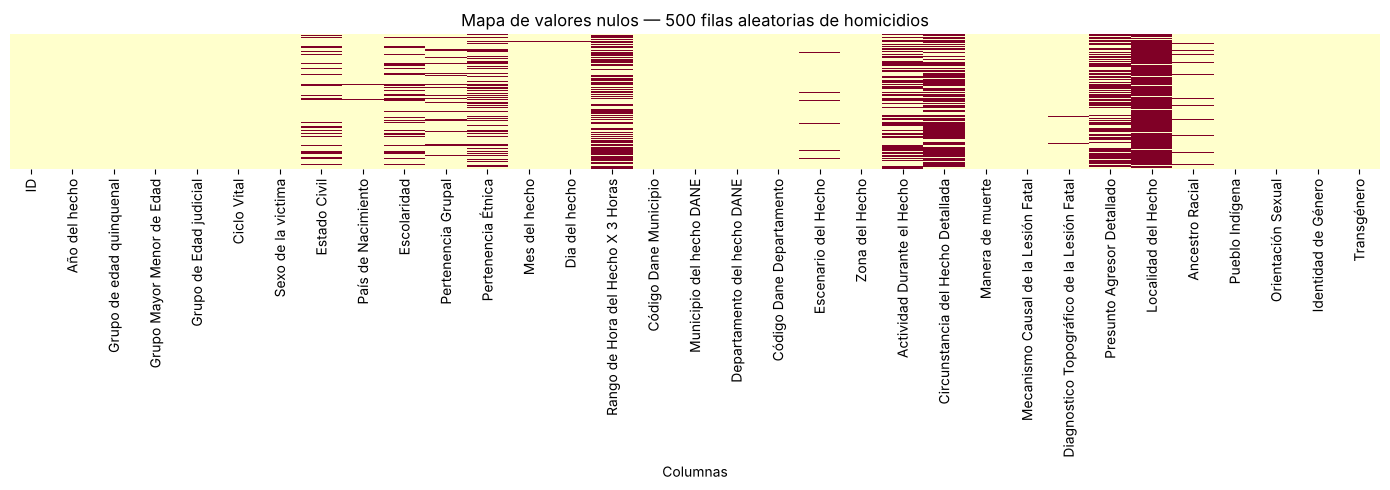

In [7]:
# Heatmap de nulos en una muestra de 500 filas
muestra_diag = df_limpieza.sample(500, random_state=42)

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(
    muestra_diag.isna(),
    cbar=False,
    yticklabels=False,
    cmap="YlOrRd",
    ax=ax
)

ax.set_title("Mapa de valores nulos — 500 filas aleatorias de homicidios")
ax.set_xlabel("Columnas")
plt.tight_layout()
plt.show()

In [8]:
nulos = df_limpieza.isnull().sum()

nulos = nulos[nulos > 0].sort_values(ascending=False)

porcentaje_nulos = (
    df_limpieza.isnull().sum() / len(df_limpieza) * 100
)

resumen_nulos = pd.DataFrame({
    "Cantidad de nulos": nulos,
    "Porcentaje (%)": porcentaje_nulos[nulos.index].round(2)
})

print(resumen_nulos)

                                            Cantidad de nulos  Porcentaje (%)
Localidad del Hecho                                    113810           90.84
Circunstancia del Hecho Detallada                       80847           64.53
Rango de Hora del Hecho X 3 Horas                       73982           59.05
Presunto Agresor Detallado                              65054           51.93
Actividad Durante el Hecho                              52747           42.10
Pertenencia Étnica                                      47221           37.69
Escolaridad                                             26745           21.35
Pertenencia Grupal                                      20741           16.56
Estado Civil                                            20184           16.11
Ancestro Racial                                         10904            8.70
Escenario del Hecho                                      7172            5.72
País de Nacimiento                                       2076   

## Imputacion de nulos

In [9]:
# Imputar ESCENARIO DEL HECHO con la moda (es categórica)
df_ejemplo = df_limpieza.copy()

moda = df_ejemplo["Escenario del Hecho"].mode()[0]
n_antes = df_ejemplo["Escenario del Hecho"].isna().sum()

df_ejemplo["Escenario del Hecho"] = (
    df_ejemplo["Escenario del Hecho"].fillna(moda)
)

n_despues = df_ejemplo["Escenario del Hecho"].isna().sum()

print(f"Escenario del Hecho: {n_antes:,} nulos ANTES → {n_despues:,} nulos DESPUÉS")
print(f"Valor imputado (moda): '{moda}'")

Escenario del Hecho: 7,172 nulos ANTES → 0 nulos DESPUÉS
Valor imputado (moda): 'Vía Pública'


In [10]:
# Imputar Municipio del hecho DANE con la moda
df_ejemplo = df_limpieza.copy()

moda = df_ejemplo["Municipio del hecho DANE"].mode()[0]
n_antes = df_ejemplo["Municipio del hecho DANE"].isna().sum()
df_ejemplo["Municipio del hecho DANE"] = df_ejemplo["Municipio del hecho DANE"].fillna(moda)
n_despues = df_ejemplo["Municipio del hecho DANE"].isna().sum()

print(f"Municipio del hecho DANE: {n_antes:,} nulos ANTES → {n_despues:,} nulos DESPUÉS")
print(f"Valor imputado (moda): '{moda}'")

Municipio del hecho DANE: 98 nulos ANTES → 0 nulos DESPUÉS
Valor imputado (moda): 'Cali'


In [11]:
# Imputar Departamento del hecho DANE con la moda
moda = df_ejemplo["Departamento del hecho DANE"].mode()[0]
n_antes = df_ejemplo["Departamento del hecho DANE"].isna().sum()
df_ejemplo["Departamento del hecho DANE"] = df_ejemplo["Departamento del hecho DANE"].fillna(moda)
n_despues = df_ejemplo["Departamento del hecho DANE"].isna().sum()

print(f"Departamento del hecho DANE: {n_antes:,} nulos ANTES → {n_despues:,} nulos DESPUÉS")
print(f"Valor imputado (moda): '{moda}'")

Departamento del hecho DANE: 97 nulos ANTES → 0 nulos DESPUÉS
Valor imputado (moda): 'Valle del Cauca'


In [12]:
# Imputar Mes del hecho con la moda
df_ejemplo = df_limpieza.copy()

moda = df_ejemplo["Mes del hecho"].mode()[0]
n_antes = df_ejemplo["Mes del hecho"].isna().sum()

df_ejemplo["Mes del hecho"] = df_ejemplo["Mes del hecho"].fillna(moda)

n_despues = df_ejemplo["Mes del hecho"].isna().sum()

print(f"Mes del hecho: {n_antes:,} nulos ANTES → {n_despues:,} nulos DESPUÉS")
print(f"Valor imputado (moda): '{moda}'")

Mes del hecho: 234 nulos ANTES → 0 nulos DESPUÉS
Valor imputado (moda): 'diciembre'


## Detección de outliers


In [13]:
# Agrupar los homicidios usando únicamente el código DANE
homicidios_municipio = (
    df_limpieza.groupby("Código Dane Municipio")
    .agg(
        Cantidad_de_homicidios=("Código Dane Municipio", "size"),
        Municipio=("Municipio del hecho DANE", "first")
    )
    .reset_index()
)

print(homicidios_municipio.head())

   Código Dane Municipio  Cantidad_de_homicidios   Municipio
0                    999                      98         NaN
1                   5001                    4729    Medellín
2                   5002                      57   Abejorral
3                   5004                       1    Abriaquí
4                   5021                       8  Alejandría


In [14]:

# Excluir temporalmente los registros sin municipio identificado
municipios_validos = homicidios_municipio[
    homicidios_municipio["Código Dane Municipio"] != 999
].copy()
# Función para detectar outliers mediante IQR
def detectar_outliers_iqr(serie):
    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)
    IQR = Q3 - Q1

    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR

    return (serie < lim_inf) | (serie > lim_sup)

# Detectar posibles outliers
outliers = detectar_outliers_iqr(
    homicidios_municipio["Cantidad_de_homicidios"]
)

print(
    f"Cantidad de posibles outliers: {outliers.sum():,} "
    f"({outliers.mean() * 100:.2f}%)"
)

print(
    homicidios_municipio.loc[outliers]
    .sort_values("Cantidad_de_homicidios", ascending=False)
)

Cantidad de posibles outliers: 122 (11.23%)
      Código Dane Municipio  Cantidad_de_homicidios         Municipio
149                   11001                   11667      Bogotá, D.C.
978                   76001                   11408  Santiago de Cali
1                      5001                    4729          Medellín
126                    8001                    3846      Barranquilla
150                   13001                    2949         Cartagena
...                     ...                     ...               ...
786                   54553                     180  Puerto Santander
668                   50006                     178           Acacías
154                   13052                     178            Arjona
1011                  76823                     178              Toro
358                   19300                     176          Guachene

[122 rows x 3 columns]


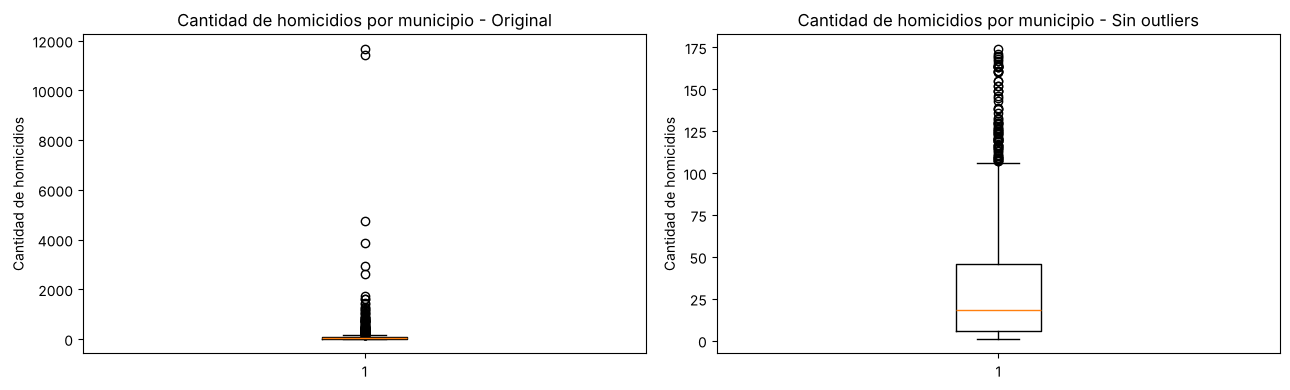

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Boxplot original
axes[0].boxplot(homicidios_municipio["Cantidad_de_homicidios"])
axes[0].set_title("Cantidad de homicidios por municipio - Original")
axes[0].set_ylabel("Cantidad de homicidios")

# Boxplot sin los posibles outliers
sin_out = homicidios_municipio.loc[
    ~outliers, "Cantidad_de_homicidios"
]

axes[1].boxplot(sin_out)
axes[1].set_title("Cantidad de homicidios por municipio - Sin outliers")
axes[1].set_ylabel("Cantidad de homicidios")

plt.tight_layout()
plt.show()

## Corrección de texto inconsistente

In [16]:
# Ver valores únicos de una columna de texto
print("Sexo de la victima valores únicos ANTES:")
print(df_limpieza["Sexo de la victima"].value_counts(dropna=False))

# Normalizar
df_limpieza["Sexo de la victima_LIMPIO"] = (
    df_limpieza["Sexo de la victima"].str.strip().str.upper()
)

print("\nSexo de la victima valores únicos DESPUÉS:")
print(df_limpieza["Sexo de la victima_LIMPIO"].value_counts(dropna=False))

Sexo de la victima valores únicos ANTES:


Sexo de la victima
Hombre           115147
Mujer             10030
Indeterminado       107
Name: count, dtype: int64

Sexo de la victima valores únicos DESPUÉS:
Sexo de la victima_LIMPIO
HOMBRE           115147
MUJER             10030
INDETERMINADO       107
Name: count, dtype: int64


In [17]:
# Ver valores únicos de una columna de texto
print("Mes del hecho valores únicos ANTES:")
print(df_limpieza["Mes del hecho"].value_counts(dropna=False))

# Normalizar
df_limpieza["Mes del hecho_LIMPIO"] = (
    df_limpieza["Mes del hecho"].str.strip().str.upper()
)

print("\nMes del hecho valores únicos DESPUÉS:")
print(df_limpieza["Mes del hecho_LIMPIO"].value_counts(dropna=False))

Mes del hecho valores únicos ANTES:
Mes del hecho
diciembre     9372
enero         8508
julio         8359
mayo          8281
agosto        8230
noviembre     8102
junio         8044
octubre       7996
marzo         7978
septiembre    7892
abril         7703
febrero       7326
Mayo          2523
Agosto        2427
Diciembre     2411
Junio         2352
Octubre       2347
Septiembre    2294
Julio         2288
Noviembre     2257
Enero         2238
Marzo         2069
Abril         2057
Febrero       1996
NaN            234
Name: count, dtype: int64

Mes del hecho valores únicos DESPUÉS:
Mes del hecho_LIMPIO
DICIEMBRE     11783
MAYO          10804
ENERO         10746
AGOSTO        10657
JULIO         10647
JUNIO         10396
NOVIEMBRE     10359
OCTUBRE       10343
SEPTIEMBRE    10186
MARZO         10047
ABRIL          9760
FEBRERO        9322
NaN             234
Name: count, dtype: int64


In [18]:
# Ver valores únicos de una columna de texto
print("Municipio del hecho DANE valores únicos ANTES:")
print(df_limpieza["Municipio del hecho DANE"].value_counts(dropna=False))

# Normalizar
df_limpieza["Municipio del hecho DANE_LIMPIO"] = (
    df_limpieza["Municipio del hecho DANE"].str.strip().str.upper()
)

print("\nMunicipio del hecho DANE valores únicos DESPUÉS:")
print(df_limpieza["Municipio del hecho DANE_LIMPIO"].value_counts(dropna=False))

Municipio del hecho DANE valores únicos ANTES:
Municipio del hecho DANE
Cali            9984
Bogotá, D.C.    8992
Medellín        4729
Barranquilla    3846
Bogotá D.C.     2674
                ... 
Taraira            1
Tuta               1
San Mateo          1
Arcabuco           1
Piedras            1
Name: count, Length: 1048, dtype: int64

Municipio del hecho DANE valores únicos DESPUÉS:
Municipio del hecho DANE_LIMPIO
CALI            9984
BOGOTÁ, D.C.    8992
MEDELLÍN        4729
BARRANQUILLA    3846
BOGOTÁ D.C.     2674
                ... 
TARAIRA            1
TUTA               1
SAN MATEO          1
ARCABUCO           1
PIEDRAS            1
Name: count, Length: 1044, dtype: int64


In [19]:
# Ver valores únicos de una columna de texto
print("Departamento del hecho DANE valores únicos ANTES:")
print(df_limpieza["Departamento del hecho DANE"].value_counts(dropna=False))

# Normalizar
df_limpieza["Departamento del hecho DANE_LIMPIO"] = (
    df_limpieza["Departamento del hecho DANE"].str.strip().str.upper()
)

print("\nDepartamento del hecho DANE valores únicos DESPUÉS:")
print(df_limpieza["Departamento del hecho DANE_LIMPIO"].value_counts(dropna=False))

Departamento del hecho DANE valores únicos ANTES:
Departamento del hecho DANE
Valle del Cauca                                             23491
Antioquia                                                   18852
Bogotá, D.C.                                                 8992
Atlántico                                                    6608
Cauca                                                        6258
Norte de Santander                                           5461
Bolívar                                                      4930
Cundinamarca                                                 4186
Nariño                                                       3660
Magdalena                                                    3382
Santander                                                    3357
Tolima                                                       2893
Huila                                                        2801
Meta                                                         278

In [20]:
# Ver valores únicos de una columna de texto
print("Zona del Hecho valores únicos ANTES:")
print(df_limpieza["Zona del Hecho"].value_counts(dropna=False))

# Normalizar
df_limpieza["Zona del Hecho_LIMPIO"] = (
    df_limpieza["Zona del Hecho"].str.strip().str.upper()
)

print("\nZona del Hecho valores únicos DESPUÉS:")
print(df_limpieza["Zona del Hecho_LIMPIO"].value_counts(dropna=False))

Zona del Hecho valores únicos ANTES:
Zona del Hecho
Cabecera municipal                                                 88108
Parte rural (vereda y campo)                                       29200
Centro poblado(corregimiento, inspección de policía y caserío)      3336
Centro poblado (corregimiento, inspección de policía y caserío)     3079
NaN                                                                 1561
Name: count, dtype: int64

Zona del Hecho valores únicos DESPUÉS:
Zona del Hecho_LIMPIO
CABECERA MUNICIPAL                                                 88108
PARTE RURAL (VEREDA Y CAMPO)                                       29200
CENTRO POBLADO(CORREGIMIENTO, INSPECCIÓN DE POLICÍA Y CASERÍO)      3336
CENTRO POBLADO (CORREGIMIENTO, INSPECCIÓN DE POLICÍA Y CASERÍO)     3079
NaN                                                                 1561
Name: count, dtype: int64


In [21]:
print(
    df_limpieza["Municipio del hecho DANE_LIMPIO"]
    .value_counts()
    .filter(like="BOGOTÁ")
)

Municipio del hecho DANE_LIMPIO
BOGOTÁ, D.C.    8992
BOGOTÁ D.C.     2674
Name: count, dtype: int64


In [22]:
# Unificar nombres de Bogotá
df_limpieza["Municipio del hecho DANE_LIMPIO"] = (
    df_limpieza["Municipio del hecho DANE_LIMPIO"]
    .replace("BOGOTÁ D.C.", "BOGOTÁ, D.C.")
)

# Verificar la corrección
print("Municipio del hecho DANE_LIMPIO:")
print(
    df_limpieza["Municipio del hecho DANE_LIMPIO"]
    .value_counts()
    .filter(like="BOGOTÁ")
)

Municipio del hecho DANE_LIMPIO:
Municipio del hecho DANE_LIMPIO
BOGOTÁ, D.C.    11666
Name: count, dtype: int64


In [23]:
# Unificar nombres inconsistentes de departamentos
df_limpieza["Departamento del hecho DANE_LIMPIO"] = (
    df_limpieza["Departamento del hecho DANE_LIMPIO"]
    .replace({
        "BOGOTÁ D.C.": "BOGOTÁ, D.C.",
        "QUINDIO": "QUINDÍO"
    })
)

# Verificar las correcciones
print("Departamentos corregidos:")
print(
    df_limpieza["Departamento del hecho DANE_LIMPIO"]
    .value_counts()
    .filter(like="BOGOTÁ")
)
print(
    df_limpieza["Departamento del hecho DANE_LIMPIO"]
    .value_counts()
    .filter(like="QUIND")
)

Departamentos corregidos:


Departamento del hecho DANE_LIMPIO
BOGOTÁ, D.C.    11666
Name: count, dtype: int64
Departamento del hecho DANE_LIMPIO
QUINDÍO    1999
Name: count, dtype: int64


## Convertir textos a numeros

In [24]:

# Ejemplo 1: One-Hot Encoding con pandas.get_dummies
df_ejemplo = df_limpieza[["Mes del hecho_LIMPIO"]].head(10).copy()
print("ANTES:")
print(df_ejemplo)

# One-Hot con drop_first=True para evitar multicolinealidad
df_dummies = pd.get_dummies(df_ejemplo, columns=["Mes del hecho_LIMPIO"], drop_first=True, dtype=int)
print("\nDESPUÉS (One-Hot, drop_first=True):")
print(df_dummies)

ANTES:
  Mes del hecho_LIMPIO
0                ENERO
1                ENERO
2                ENERO
3                ENERO
4                ENERO
5                ENERO
6                ENERO
7                ENERO
8                ENERO
9                ENERO

DESPUÉS (One-Hot, drop_first=True):
Empty DataFrame
Columns: []
Index: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [25]:
df_ejemplo = df_limpieza[["Municipio del hecho DANE_LIMPIO"]].head(10).copy()

print("ANTES:")
print(df_ejemplo)

df_dummies = pd.get_dummies(df_ejemplo,columns=["Municipio del hecho DANE_LIMPIO"],drop_first=True,dtype=int)
print("\nDESPUÉS (One-Hot, drop_first=True):")
print(df_dummies)

ANTES:
  Municipio del hecho DANE_LIMPIO
0                         ACACÍAS
1                          GUAMAL
2                         AGUADAS
3                         AGUADAS
4                           ANDES
5                           ANDES
6                           ANDES
7                           ANDES
8                           ANDES
9                     PUEBLO RICO

DESPUÉS (One-Hot, drop_first=True):
   Municipio del hecho DANE_LIMPIO_AGUADAS  \
0                                        0   
1                                        0   
2                                        1   
3                                        1   
4                                        0   
5                                        0   
6                                        0   
7                                        0   
8                                        0   
9                                        0   

   Municipio del hecho DANE_LIMPIO_ANDES  \
0                              

In [26]:
df_ejemplo = df_limpieza[["Sexo de la victima_LIMPIO"]].head(10).copy()

print("ANTES:")
print(df_ejemplo)

df_dummies = pd.get_dummies(
    df_ejemplo,
    columns=["Sexo de la victima_LIMPIO"],
    drop_first=True,
    dtype=int
)

print("\nDESPUÉS (One-Hot, drop_first=True):")
print(df_dummies)

ANTES:
  Sexo de la victima_LIMPIO
0                    HOMBRE
1                    HOMBRE
2                    HOMBRE
3                     MUJER
4                    HOMBRE
5                    HOMBRE
6                    HOMBRE
7                    HOMBRE
8                    HOMBRE
9                    HOMBRE

DESPUÉS (One-Hot, drop_first=True):
   Sexo de la victima_LIMPIO_MUJER
0                                0
1                                0
2                                0
3                                1
4                                0
5                                0
6                                0
7                                0
8                                0
9                                0


In [27]:
# Ejemplo 2: One-Hot con sklearn
from sklearn.preprocessing import OneHotEncoder

cols_categoricas = [
    "Mes del hecho_LIMPIO",
    "Municipio del hecho DANE_LIMPIO",
    "Sexo de la victima_LIMPIO"
]

encoder = OneHotEncoder(
    sparse_output=False,
    drop="first",
    handle_unknown="ignore"
)

encoded = encoder.fit_transform(
    df_limpieza[cols_categoricas].fillna("DESCONOCIDO")
)

nombres_cols = encoder.get_feature_names_out(cols_categoricas)

print(f"Columnas originales: {len(cols_categoricas)}")
print(f"Columnas después de OneHot: {encoded.shape[1]}")
print("\nNombres de columnas generadas:")

for n in nombres_cols:
    print(f"  {n}")

# Convertir las variables codificadas en un DataFrame
df_codificadas = pd.DataFrame(
    encoded,
    columns=nombres_cols,
    index=df_limpieza.index
)

# Añadir las columnas codificadas sin eliminar las originales
df_limpieza = pd.concat(
    [df_limpieza, df_codificadas],
    axis=1
)

print("Dimensiones después de la codificación:", df_limpieza.shape)



Columnas originales: 3
Columnas después de OneHot: 1056

Nombres de columnas generadas:
  Mes del hecho_LIMPIO_AGOSTO
  Mes del hecho_LIMPIO_DESCONOCIDO
  Mes del hecho_LIMPIO_DICIEMBRE
  Mes del hecho_LIMPIO_ENERO
  Mes del hecho_LIMPIO_FEBRERO
  Mes del hecho_LIMPIO_JULIO
  Mes del hecho_LIMPIO_JUNIO
  Mes del hecho_LIMPIO_MARZO
  Mes del hecho_LIMPIO_MAYO
  Mes del hecho_LIMPIO_NOVIEMBRE
  Mes del hecho_LIMPIO_OCTUBRE
  Mes del hecho_LIMPIO_SEPTIEMBRE
  Municipio del hecho DANE_LIMPIO_ABREGO
  Municipio del hecho DANE_LIMPIO_ABRIAQUÍ
  Municipio del hecho DANE_LIMPIO_ACACÍAS
  Municipio del hecho DANE_LIMPIO_ACANDÍ
  Municipio del hecho DANE_LIMPIO_ACEVEDO
  Municipio del hecho DANE_LIMPIO_ACHÍ
  Municipio del hecho DANE_LIMPIO_AGRADO
  Municipio del hecho DANE_LIMPIO_AGUA DE DIOS
  Municipio del hecho DANE_LIMPIO_AGUACHICA
  Municipio del hecho DANE_LIMPIO_AGUACHÍCA
  Municipio del hecho DANE_LIMPIO_AGUADA
  Municipio del hecho DANE_LIMPIO_AGUADAS
  Municipio del hecho DANE_LIMPIO_

Dimensiones después de la codificación: (125284, 1094)


## Transformación logaritmica

In [28]:
import numpy as np

# Contar los homicidios registrados por municipio
casos_por_municipio = df_limpieza["Municipio del hecho DANE_LIMPIO"].value_counts()
print(f"Municipios: {len(casos_por_municipio):,}")
print("Casos por municipio — estadísticos:")
print(casos_por_municipio.describe().round(2))
print(f"\nAsimetría original: {casos_por_municipio.skew():.2f}")

# Aplicar transformación logarítmica
casos_log = np.log1p(casos_por_municipio)
print(f"Asimetría después de log: {casos_log.skew():.2f}")

Municipios: 1,042
Casos por municipio — estadísticos:
count     1042.00
mean       120.14
std        552.54
min          1.00
25%          7.00
50%         24.00
75%         80.75
max      11666.00
Name: count, dtype: float64

Asimetría original: 15.47
Asimetría después de log: 0.43


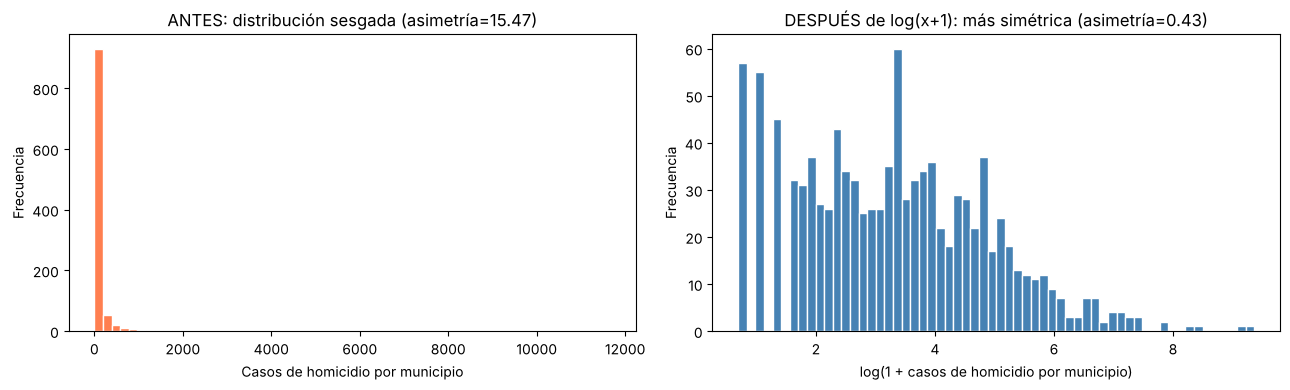

In [29]:
# Comparar visualmente: histograma antes y después
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(casos_por_municipio, bins=60, color="coral", edgecolor="white")
axes[0].set_title(f"ANTES: distribución sesgada (asimetría={casos_por_municipio.skew():.2f})")
axes[0].set_xlabel("Casos de homicidio por municipio")
axes[0].set_ylabel("Frecuencia")
axes[1].hist(casos_log, bins=60, color="steelblue", edgecolor="white")
axes[1].set_title(f"DESPUÉS de log(x+1): más simétrica (asimetría={casos_log.skew():.2f})")
axes[1].set_xlabel("log(1 + casos de homicidio por municipio)")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

---
## Pipeline final de limpieza (versión que se guarda en el parquet)
Las celdas anteriores son el **diagnóstico** y las **pruebas** de cada técnica: las imputaciones se probaron sobre copias (`df_ejemplo`) y el One-Hot de prueba incluía los 1.000+ municipios. En esta sección se aplica todo, en orden, sobre un solo DataFrame: **`df_limpio`**. Ese es el que se guarda en `datos_limpios.parquet` y el que usa la Fase C.

### 1. Normalización de texto
La misma categoría aparece escrita de varias formas (mayúsculas, espacios antes del paréntesis, comas, punto final, hora con y sin paréntesis). Se unifican todas las columnas de texto con una sola función. "POR DETERMINAR" y "NO APLICA" también se tratan como dato faltante.

In [30]:
# Partir de las 33 columnas originales (con "Sin información" ya en NaN)
# Se usa df_limpieza[df.columns] para no arrastrar las columnas One-Hot de prueba
df_limpio = df_limpieza[df.columns].copy()

def normalizar_texto(serie):
    """Mayúsculas, sin espacios extra y con la misma puntuación."""
    serie = serie.str.strip().str.upper()
    serie = serie.str.replace(" (", "(", regex=False)
    serie = serie.str.replace(", ", ",", regex=False)
    serie = serie.str.replace(",", ", ", regex=False)
    serie = serie.str.replace(".)", ")", regex=False)
    serie = serie.str.replace("  ", " ", regex=False)
    return serie

# Aplicar la normalización a todas las columnas de texto
columnas_texto = df_limpio.select_dtypes(include=["object", "string"]).columns
for columna in columnas_texto:
    df_limpio[columna] = normalizar_texto(df_limpio[columna])

# "Por determinar" y "No aplica" tampoco son un dato real: se pasan a NaN
df_limpio = df_limpio.replace(["POR DETERMINAR", "NO APLICA"], np.nan)

# La hora viene a veces con paréntesis y a veces sin ellos
df_limpio["Rango de Hora del Hecho X 3 Horas"] = (
    df_limpio["Rango de Hora del Hecho X 3 Horas"].str.strip("()"))

print("Valores distintos ANTES vs DESPUÉS:")
for columna in ["Estado Civil", "Escenario del Hecho", "Zona del Hecho", "Rango de Hora del Hecho X 3 Horas", "Mes del hecho"]:
    print(f"  {columna}: {df[columna].nunique()} → {df_limpio[columna].nunique()}")

Valores distintos ANTES vs DESPUÉS:
  Estado Civil: 11 → 5
  Escenario del Hecho: 72 → 40
  Zona del Hecho: 5 → 3
  Rango de Hora del Hecho X 3 Horas: 18 → 8
  Mes del hecho: 25 → 12


**Resultado:** Estado Civil pasa de 11 a 5 valores, Escenario de 72 a 40, Zona de 5 a 3, Rango de hora de 18 a 8 y Mes de 25 a 12. Eran la misma categoría escrita distinto.

### 2. Unificar vocabularios que cambiaron entre años

In [31]:
# Unificar vocabularios que cambiaron entre años
mapa_mecanismo = {
    "CORTO PUNZANTE": "CORTOPUNZANTE",
    "CORTO CONTUNDENTE": "CORTOCONTUNDENTE",
    "MECANISMO O AGENTE EXPLOSIVO": "AGENTES Y MECANISMO EXPLOSIVO",
    "AGENTE O MECANISMO EXPLOSIVO": "AGENTES Y MECANISMO EXPLOSIVO",
    "OTRA": "OTROS",
    "OTRO": "OTROS",
}
df_limpio["Mecanismo Causal de la Lesión Fatal"] = (
    df_limpio["Mecanismo Causal de la Lesión Fatal"].replace(mapa_mecanismo))

df_limpio["Grupo Mayor Menor de Edad"] = df_limpio["Grupo Mayor Menor de Edad"].replace({
    "B) MAYORES DE EDAD(>18 AÑOS)": "MAYOR DE EDAD",
    "B) MAYOR DE EDAD(>18 AÑOS)": "MAYOR DE EDAD",
    "A) MENORES DE EDAD(<18 AÑOS)": "MENOR DE EDAD",
    "A) MENOR DE EDAD(<18 AÑOS)": "MENOR DE EDAD",
    "C) SIN INFORMACIÓN": np.nan,
})

# Departamentos con dos escrituras (las mismas que corrigió la integrante arriba)
df_limpio["Departamento del hecho DANE"] = (
    df_limpio["Departamento del hecho DANE"].replace({"BOGOTÁ D.C.": "BOGOTÁ, D.C.", "QUINDIO": "QUINDÍO"}))

# Municipio: se usa el nombre más frecuente de cada código DANE
# Así "CALI" y "SANTIAGO DE CALI" (código 76001) quedan con un solo nombre
nombre_por_codigo = (df_limpio.groupby("Código Dane Municipio")["Municipio del hecho DANE"]
                     .agg(lambda nombres: nombres.mode()[0] if nombres.notna().any() else np.nan))
df_limpio["Municipio del hecho DANE"] = df_limpio["Código Dane Municipio"].map(nombre_por_codigo)

print("Mecanismos:", df["Mecanismo Causal de la Lesión Fatal"].nunique(), "→", df_limpio["Mecanismo Causal de la Lesión Fatal"].nunique())
print("Municipios:", df["Municipio del hecho DANE"].nunique(), "→", df_limpio["Municipio del hecho DANE"].nunique())
print(df_limpio[df_limpio["Código Dane Municipio"] == 76001]["Municipio del hecho DANE"].value_counts())

Mecanismos: 24 → 15
Municipios: 1048 → 1005
Municipio del hecho DANE
CALI    11408
Name: count, dtype: int64


**Resultado:** el mecanismo causal pasa de 24 a 15 categorías (ej. "CORTO PUNZANTE" = "CORTOPUNZANTE"). El municipio se toma del **código DANE**, así "CALI" y "SANTIAGO DE CALI" quedan como un solo municipio con 11.408 casos.

### 3. Columnas y filas eliminadas
| Columna | Motivo |
|---|---|
| Localidad del Hecho | 90,8 % nulos |
| Circunstancia del Hecho Detallada | 64,5 % nulos |
| Presunto Agresor Detallado | 51,9 % nulos |
| Orientación Sexual, Identidad de Género, Transgénero, Pueblo Indígena | La variable "No había sido implementada" en la mayoría de años |
| Manera de muerte | Un solo valor: no aporta información |
| Grupo de Edad judicial | Repite el grupo de edad quinquenal |
| Pertenencia Grupal | 88 categorías desordenadas |
| Diagnóstico Topográfico | Es una consecuencia del mecanismo (no sirve para predecirlo) |

Regla usada: **más del 50 % de nulos → se elimina la columna**, porque imputar más de la mitad de los datos sería inventarlos.

In [32]:
# Eliminar columnas que no sirven para el análisis
columnas_eliminar = [
    "Localidad del Hecho",                 # 90,8 % nulos
    "Circunstancia del Hecho Detallada",   # 64,5 % nulos
    "Presunto Agresor Detallado",          # 51,9 % nulos
    "Orientación Sexual",                  # 66 % "No había sido implementada"
    "Identidad de Género",                 # 66 % "No había sido implementada"
    "Transgénero",                         # 66 % "No había sido implementada"
    "Pueblo Indígena",                     # casi todo "No había sido implementada"
    "Manera de muerte",                    # un solo valor (todas son homicidio)
    "Grupo de Edad judicial",              # repite la información del grupo quinquenal
    "Pertenencia Grupal",                  # 88 categorías muy desordenadas
    "Diagnostico Topográfico de la Lesión Fatal",  # es consecuencia del mecanismo
]
df_limpio = df_limpio.drop(columns=columnas_eliminar)

# Las 98 filas sin municipio (código 999) no se pueden ubicar en el mapa
filas_antes = len(df_limpio)
df_limpio = df_limpio[df_limpio["Código Dane Municipio"] != 999].copy()
print(f"Columnas: {df.shape[1]} → {df_limpio.shape[1]}")
print(f"Filas: {filas_antes:,} → {len(df_limpio):,} (se quitan {filas_antes - len(df_limpio)} sin municipio)")

Columnas: 33 → 22
Filas: 125,284 → 125,186 (se quitan 98 sin municipio)


**Resultado:** quedan 22 columnas. Las 98 filas con código de municipio 999 (sin información) se eliminan (0,08 % del total): imputar la moda pondría esos casos en Cali sin ningún soporte, y son demasiado pocas para afectar el análisis.

### 4. Imputación de nulos — estrategias 1 (moda) y 2 (categoría "SIN INFORMACIÓN")

In [33]:
# Estrategia 1 — MODA para categóricas con pocos nulos (< 10 %)
columnas_moda = ["Escenario del Hecho", "Zona del Hecho", "Mes del hecho", "Dia del hecho",
                 "Ciclo Vital", "Grupo Mayor Menor de Edad", "Grupo de edad quinquenal",
                 "País de Nacimiento", "Ancestro Racial"]
for columna in columnas_moda:
    moda = df_limpio[columna].mode()[0]
    n_nulos = df_limpio[columna].isna().sum()
    df_limpio[columna] = df_limpio[columna].fillna(moda)
    print(f"MODA    | {columna}: {n_nulos:,} nulos → '{moda}'")

# Estrategia 2 — categoría "SIN INFORMACIÓN" cuando faltan muchos datos (16 % a 59 %)
# Rellenar con la moda inventaría miles de horas o estados civiles que no conocemos
columnas_constante = ["Rango de Hora del Hecho X 3 Horas", "Estado Civil", "Actividad Durante el Hecho", "Pertenencia Étnica"]
for columna in columnas_constante:
    n_nulos = df_limpio[columna].isna().sum()
    df_limpio[columna] = df_limpio[columna].fillna("SIN INFORMACIÓN")
    print(f"CONSTANTE | {columna}: {n_nulos:,} nulos → 'SIN INFORMACIÓN'")

MODA    | Escenario del Hecho: 7,139 nulos → 'VÍA PÚBLICA'
MODA    | Zona del Hecho: 1,535 nulos → 'CABECERA MUNICIPAL'
MODA    | Mes del hecho: 230 nulos → 'DICIEMBRE'
MODA    | Dia del hecho: 230 nulos → 'DOMINGO'
MODA    | Ciclo Vital: 25 nulos → '(29 A 59) ADULTEZ'
MODA    | Grupo Mayor Menor de Edad: 25 nulos → 'MAYOR DE EDAD'
MODA    | Grupo de edad quinquenal: 25 nulos → '(20 A 24)'
MODA    | País de Nacimiento: 2,072 nulos → 'COLOMBIA'
MODA    | Ancestro Racial: 10,889 nulos → 'MESTIZO'
CONSTANTE | Rango de Hora del Hecho X 3 Horas: 73,901 nulos → 'SIN INFORMACIÓN'
CONSTANTE | Estado Civil: 20,865 nulos → 'SIN INFORMACIÓN'


CONSTANTE | Actividad Durante el Hecho: 52,675 nulos → 'SIN INFORMACIÓN'
CONSTANTE | Pertenencia Étnica: 47,133 nulos → 'SIN INFORMACIÓN'


**Justificación por columna:**
| Columna | % nulos | Estrategia | Por qué |
|---|---|---|---|
| Escenario, Zona, Mes, Día, Ciclo vital, Grupo de edad, Mayor/menor, País, Ancestro | 0,02 % – 8,7 % | **Moda** | Son categóricas y faltan pocos datos: la moda casi no cambia la distribución |
| Rango de hora | 59 % | **"SIN INFORMACIÓN"** | Con la moda se inventarían 73.901 horas; mejor dejar la ausencia como categoría |
| Estado civil, Actividad, Pertenencia étnica | 16 % – 42 % | **"SIN INFORMACIÓN"** | Demasiados nulos para la moda; el modelo puede aprender si la ausencia es informativa |

### 5. Ordinal Encoding — variables con orden natural
El grupo de edad, el ciclo vital y la escolaridad tienen un orden (de menor a mayor), por eso se codifican con números consecutivos y **no** con One-Hot. Se usa `OrdinalEncoder` con el orden explícito para edad y ciclo vital, y un diccionario para escolaridad, porque esta tenía 17 escrituras para 8 niveles.

In [34]:
# Ordinal Encoding para variables con orden natural
from sklearn.preprocessing import OrdinalEncoder

orden_edad = ["(00 A 04)", "(05 A 09)", "(10 A 14)", "(15 A 17)", "(18 A 19)", "(20 A 24)", "(25 A 29)",
              "(30 A 34)", "(35 A 39)", "(40 A 44)", "(45 A 49)", "(50 A 54)", "(55 A 59)", "(60 A 64)",
              "(65 A 69)", "(70 A 74)", "(75 A 79)", "(80 Y MÁS)"]
orden_ciclo = ["(00 A 05) PRIMERA INFANCIA", "(06 A 11) INFANCIA", "(12 A 17) ADOLESCENCIA",
               "(18 A 28) JUVENTUD", "(29 A 59) ADULTEZ", "(MÁS DE 60) ADULTO MAYOR"]

encoder_ordinal = OrdinalEncoder(categories=[orden_edad, orden_ciclo])
valores_ordinales = encoder_ordinal.fit_transform(df_limpio[["Grupo de edad quinquenal", "Ciclo Vital"]])
df_limpio["grupo_edad_ord"] = valores_ordinales[:, 0].astype(int)
df_limpio["ciclo_vital_ord"] = valores_ordinales[:, 1].astype(int)

# Escolaridad: varias escrituras para el mismo nivel, se agrupan en 8 niveles (0 a 7)
mapa_escolaridad = {
    "SIN ESCOLARIDAD": 0, "NINGUNA": 0,
    "PREESCOLAR": 1, "EDUCACIÓN INICIAL Y EDUCACIÓN PREESCOLAR": 1,
    "BÁSICA PRIMARIA": 2, "EDUCACIÓN BÁSICA PRIMARIA": 2,
    "BÁSICA SECUNDARIA": 3, "EDUCACIÓN BÁSICA SECUNDARIA O SECUNDARIA BAJA": 3,
    "EDUCACIÓN MEDIA O SECUNDARIA ALTA": 4,
    "TECNOLÓGICA": 5, "EDUCACIÓN TÉCNICA PROFESIONAL Y TECNOLÓGICA": 5,
    "UNIVERSITARIO": 6, "PROFESIONAL": 6,
    "ESPECIALIZACIÓN, MAESTRÍA O EQUIVALENTE": 7, "MAESTRÍA": 7, "DOCTORADO O EQUIVALENTE": 7,
}
df_limpio["escolaridad_ord"] = df_limpio["Escolaridad"].map(mapa_escolaridad)

# Mes y día como número (también tienen orden)
meses = {"ENERO": 1, "FEBRERO": 2, "MARZO": 3, "ABRIL": 4, "MAYO": 5, "JUNIO": 6, "JULIO": 7,
         "AGOSTO": 8, "SEPTIEMBRE": 9, "OCTUBRE": 10, "NOVIEMBRE": 11, "DICIEMBRE": 12}
dias = {"LUNES": 1, "MARTES": 2, "MIÉRCOLES": 3, "JUEVES": 4, "VIERNES": 5, "SÁBADO": 6, "DOMINGO": 7}
df_limpio["mes_num"] = df_limpio["Mes del hecho"].map(meses)
df_limpio["dia_num"] = df_limpio["Dia del hecho"].map(dias)

print(df_limpio[["Grupo de edad quinquenal", "grupo_edad_ord", "Ciclo Vital", "ciclo_vital_ord",
                                "Escolaridad", "escolaridad_ord"]].drop_duplicates().head(8))

  Grupo de edad quinquenal  grupo_edad_ord         Ciclo Vital  \
0                (20 A 24)               5  (18 A 28) JUVENTUD   
1                (25 A 29)               6  (18 A 28) JUVENTUD   
2                (20 A 24)               5  (18 A 28) JUVENTUD   
3                (30 A 34)               7   (29 A 59) ADULTEZ   
4                (25 A 29)               6  (18 A 28) JUVENTUD   
6                (35 A 39)               8   (29 A 59) ADULTEZ   
7                (35 A 39)               8   (29 A 59) ADULTEZ   
8                (20 A 24)               5  (18 A 28) JUVENTUD   

   ciclo_vital_ord        Escolaridad  escolaridad_ord  
0                3    BÁSICA PRIMARIA              2.0  
1                3    BÁSICA PRIMARIA              2.0  
2                3  BÁSICA SECUNDARIA              3.0  
3                4         PREESCOLAR              1.0  
4                3         PREESCOLAR              1.0  
6                4                NaN              NaN  
7     

### 6. Imputación con mediana — estrategia 3 (variables numéricas / ordinales)

In [35]:
# Estrategia 3 — MEDIANA para variables numéricas / ordinales
# Edad aproximada = punto medio del grupo quinquenal (igual que en la Fase A)
def punto_medio_edad(texto):
    """Convierte '(20 A 24)' en 22."""
    if texto == "(80 Y MÁS)":
        return 82
    partes = texto.strip("()").split(" A ")
    return (int(partes[0]) + int(partes[1])) / 2

df_limpio["edad_aprox"] = df_limpio["Grupo de edad quinquenal"].apply(punto_medio_edad)

# Escolaridad ordinal: 21 % de nulos, se usa la mediana porque es ordinal y no simétrica
mediana_esc = df_limpio["escolaridad_ord"].median()
media_esc = df_limpio["escolaridad_ord"].mean()
n_nulos = df_limpio["escolaridad_ord"].isna().sum()
df_limpio["escolaridad_ord"] = df_limpio["escolaridad_ord"].fillna(mediana_esc).astype(int)
print(f"MEDIANA | escolaridad_ord: {n_nulos:,} nulos → {mediana_esc} (la media sería {media_esc:.2f}, un nivel que no existe)")

# La columna de texto de escolaridad ya queda representada por escolaridad_ord
df_limpio = df_limpio.drop(columns=["Escolaridad"])
print("\nNulos que quedan en todo el DataFrame:", df_limpio.isna().sum().sum())

MEDIANA | escolaridad_ord: 26,758 nulos → 2.0 (la media sería 2.45, un nivel que no existe)

Nulos que quedan en todo el DataFrame: 272


**Justificación:** la escolaridad ordinal tiene 21 % de nulos. Se usa la **mediana** (nivel 2 = básica primaria) y no la media porque la variable es ordinal y está sesgada: la media (2,45) sería un nivel que no existe. Los 272 nulos que quedan son del mecanismo causal ("POR DETERMINAR") y se eliminan en el punto 8, porque no tienen variable objetivo.

### 7. Outliers — IQR (edad) y Z-score (homicidios por municipio)

In [36]:
# Outliers con IQR (edad) y Z-score (homicidios por municipio)
q1 = df_limpio["edad_aprox"].quantile(0.25)
q3 = df_limpio["edad_aprox"].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
outliers_edad = df_limpio["edad_aprox"] > limite_superior
print(f"IQR edad: Q1={q1}, Q3={q3}, límite superior={limite_superior}")
print(f"  Víctimas por encima del límite: {outliers_edad.sum():,} ({outliers_edad.mean()*100:.1f} %)")

# Homicidios del municipio en cada registro (sirve para el modelo y el clustering)
df_limpio["homicidios_municipio"] = (
    df_limpio.groupby("Código Dane Municipio")["ID"].transform("count"))
conteo_mun = df_limpio.groupby("Código Dane Municipio")["ID"].count()
z_score = (conteo_mun - conteo_mun.mean()) / conteo_mun.std()
print(f"\nZ-score homicidios por municipio: {(z_score.abs() > 3).sum()} municipios con |z| > 3")
print(conteo_mun[z_score.abs() > 3].sort_values(ascending=False).head(10))

IQR edad: Q1=22.0, Q3=37.0, límite superior=59.5
  Víctimas por encima del límite: 5,641 (4.5 %)

Z-score homicidios por municipio: 6 municipios con |z| > 3
Código Dane Municipio
11001    11667
76001    11408
5001      4729
8001      3846
13001     2949
54001     2599
Name: ID, dtype: int64


**Decisión: se CONSERVAN.** Con IQR, el 4,5 % de las víctimas (mayores de 59,5 años) sale como atípico, pero son edades reales de adultos mayores. Con Z-score, 6 municipios superan |z| > 3 (Bogotá, Cali, Medellín, Barranquilla, Cartagena y Cúcuta): son las grandes ciudades, justo donde se concentra el problema. Eliminarlos borraría el 30 % de los casos. En vez de quitarlos se usa la **transformación logarítmica** y el **RobustScaler**, que reducen su efecto.

### 8. Transformación logarítmica y variable objetivo

In [37]:
# Transformación logarítmica de la variable sesgada
df_limpio["homicidios_municipio_log"] = np.log1p(df_limpio["homicidios_municipio"])
print(f"Asimetría homicidios_municipio: {conteo_mun.skew():.2f} → con log: {np.log1p(conteo_mun).skew():.2f}")

# Las 272 filas con mecanismo "POR DETERMINAR" no tienen variable objetivo: se eliminan
df_limpio = df_limpio.dropna(subset=["Mecanismo Causal de la Lesión Fatal"]).copy()
print("Filas después de quitar mecanismo desconocido:", f"{len(df_limpio):,}")

# Variable objetivo para la Fase C: ¿el homicidio fue con arma de fuego?
df_limpio["es_arma_fuego"] = (
    df_limpio["Mecanismo Causal de la Lesión Fatal"] == "PROYECTIL DE ARMA DE FUEGO").astype(int)
print("\nVariable objetivo es_arma_fuego:")
print(df_limpio["es_arma_fuego"].value_counts(normalize=True).round(3))

Asimetría homicidios_municipio: 16.22 → con log: 0.46


Filas después de quitar mecanismo desconocido: 124,914

Variable objetivo es_arma_fuego:
es_arma_fuego
1    0.742
0    0.258
Name: proportion, dtype: float64


**Resultado:** `homicidios_municipio` tiene asimetría 16,2; con `log(1 + x)` baja a 0,46 (casi simétrica). Se eliminan las 272 filas con mecanismo "POR DETERMINAR" porque no tienen variable objetivo. La variable objetivo de la Fase C es **`es_arma_fuego`** (1 = arma de fuego): 74,2 % de los casos, así que las clases están desbalanceadas.

### 9. One-Hot Encoding (`get_dummies` con `drop_first=True`) — variables nominales

In [38]:
# One-Hot Encoding (get_dummies con drop_first=True) para las nominales
# Se usa Departamento (33 valores) y no Municipio (1.000+), para no crear 1.000 columnas
# Escenario tiene 40 categorías: las que tienen menos de 1.000 casos se agrupan en "OTROS"
conteo_escenario = df_limpio["Escenario del Hecho"].value_counts()
escenarios_raros = conteo_escenario[conteo_escenario < 1000].index
df_limpio.loc[df_limpio["Escenario del Hecho"].isin(escenarios_raros), "Escenario del Hecho"] = "OTROS"

columnas_onehot = ["Sexo de la victima", "Zona del Hecho", "Escenario del Hecho", "Rango de Hora del Hecho X 3 Horas",
                   "Departamento del hecho DANE", "Estado Civil", "Actividad Durante el Hecho"]
print("Categorías por columna:")
for columna in columnas_onehot:
    print(f"  {columna}: {df_limpio[columna].nunique()}")

df_dummies = pd.get_dummies(df_limpio[columnas_onehot], drop_first=True, dtype=int)
df_dummies.columns = ["oh_" + c for c in df_dummies.columns]
df_limpio = pd.concat([df_limpio, df_dummies], axis=1)
print(f"\nColumnas One-Hot creadas: {df_dummies.shape[1]}")
print("Dimensiones finales:", df_limpio.shape)

Categorías por columna:
  Sexo de la victima: 3
  Zona del Hecho: 3
  Escenario del Hecho: 11
  Rango de Hora del Hecho X 3 Horas: 9
  Departamento del hecho DANE: 33
  Estado Civil: 6
  Actividad Durante el Hecho: 20



Columnas One-Hot creadas: 78
Dimensiones finales: (124914, 108)


**Justificación:** sexo, zona, escenario, franja horaria, departamento, estado civil y actividad **no tienen orden**, por eso van con One-Hot. `drop_first=True` quita una categoría de cada variable para evitar multicolinealidad. Se codifica el **departamento (33)** y no el municipio (1.000+), porque este último crearía más de mil columnas casi vacías. Los escenarios con menos de 1.000 casos se agrupan en "OTROS". Las columnas creadas empiezan por `oh_`.

### 10. Estandarización y normalización — Min-Max, Z-score y RobustScaler

       edad original  edad Min-Max  edad Z-score  hom. municipio Robust  \
count      124914.00     124914.00     124914.00              124914.00   
mean           32.65          0.38          0.00                   0.59   
std            12.97          0.16          1.00                   1.16   
min             2.00          0.00         -2.36                  -0.20   
25%            22.00          0.25         -0.82                  -0.16   
50%            32.00          0.38         -0.05                   0.00   
75%            37.00          0.44          0.34                   0.84   
max            82.00          1.00          3.80                   2.97   

       log hom. Z-score  
count         124914.00  
mean               0.00  
std                1.00  
min               -3.05  
25%               -0.75  
50%                0.03  
75%                0.88  
max                1.46  


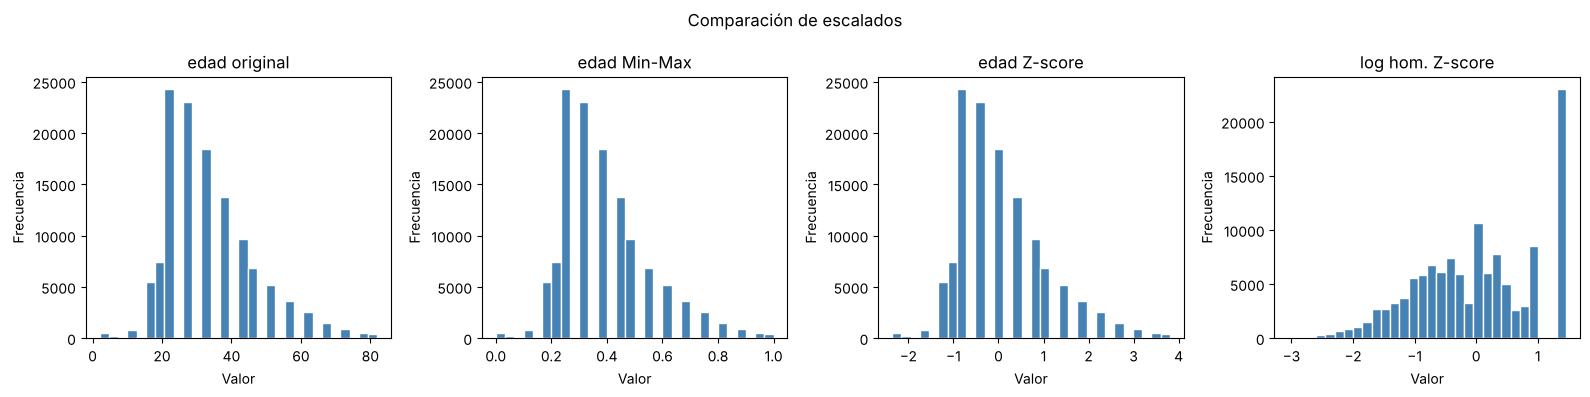

In [39]:
# Comparar Min-Max, Z-score y RobustScaler
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

df_escalas = pd.DataFrame({
    "edad original": df_limpio["edad_aprox"],
    "edad Min-Max": MinMaxScaler().fit_transform(df_limpio[["edad_aprox"]])[:, 0],
    "edad Z-score": StandardScaler().fit_transform(df_limpio[["edad_aprox"]])[:, 0],
    "hom. municipio Robust": RobustScaler().fit_transform(df_limpio[["homicidios_municipio"]])[:, 0],
    "log hom. Z-score": StandardScaler().fit_transform(df_limpio[["homicidios_municipio_log"]])[:, 0],
})
print(df_escalas.describe().round(2))

# Gráfico: la forma no cambia, cambia la escala
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i, columna in enumerate(["edad original", "edad Min-Max", "edad Z-score", "log hom. Z-score"]):
    axes[i].hist(df_escalas[columna], bins=30, color="steelblue", edgecolor="white")
    axes[i].set_title(columna)
    axes[i].set_xlabel("Valor")
    axes[i].set_ylabel("Frecuencia")
plt.suptitle("Comparación de escalados")
plt.tight_layout()
plt.savefig("figuras/escalados.png", dpi=150)
plt.show()

**Justificación:**
- **Z-score (StandardScaler)** para la edad y el log de homicidios: quedan con media 0 y desviación 1, y su distribución es razonablemente simétrica.
- **Min-Max** lleva la edad a [0, 1]; sirve para KNN y redes neuronales, pero es sensible a extremos.
- **RobustScaler** para `homicidios_municipio`: usa la mediana y el IQR, así que no lo dominan Bogotá y Cali.

**Importante:** el escalado **no se guarda** en el parquet. Para no tener *data leakage*, en la Fase C el escalador se ajusta **solo con el conjunto de entrenamiento**, después del `train_test_split`.

### 11. Verificación final

In [40]:
# Resumen del DataFrame limpio antes de guardarlo
print("Filas y columnas:", df_limpio.shape)
print("Nulos totales:", df_limpio.isna().sum().sum())
print("Filas duplicadas:", df_limpio.duplicated().sum())
print("\nColumnas que no son One-Hot:")
print([c for c in df_limpio.columns if not c.startswith("oh_")])

Filas y columnas: (124914, 108)
Nulos totales: 0


Filas duplicadas: 0

Columnas que no son One-Hot:
['ID', 'Año del hecho', 'Grupo de edad quinquenal', 'Grupo Mayor Menor de Edad', 'Ciclo Vital', 'Sexo de la victima', 'Estado Civil', 'País de Nacimiento', 'Pertenencia Étnica', 'Mes del hecho', 'Dia del hecho', 'Rango de Hora del Hecho X 3 Horas', 'Código Dane Municipio', 'Municipio del hecho DANE', 'Departamento del hecho DANE', 'Código Dane Departamento', 'Escenario del Hecho', 'Zona del Hecho', 'Actividad Durante el Hecho', 'Mecanismo Causal de la Lesión Fatal', 'Ancestro Racial', 'grupo_edad_ord', 'ciclo_vital_ord', 'escolaridad_ord', 'mes_num', 'dia_num', 'edad_aprox', 'homicidios_municipio', 'homicidios_municipio_log', 'es_arma_fuego']


### 12. Guardar el DataFrame limpio

In [41]:
from pathlib import Path

# Guardar el DataFrame limpio en la carpeta entrega
ruta_salida = Path("datos_limpios.parquet")

df_limpio.to_parquet(ruta_salida, index=False)

print("Archivo guardado en:", ruta_salida.resolve())

Archivo guardado en: /tmp/claude-0/-home-claude/59d1f8ba-ecae-501e-bb4f-8e5557ba6ae2/scratchpad/limpio/PROYECTO_P2P3_copia/entrega/datos_limpios.parquet


In [42]:
df_comprobacion = pd.read_parquet("datos_limpios.parquet")

print("Dimensiones del DataFrame limpio:", df_limpio.shape)
print("Dimensiones del archivo guardado:", df_comprobacion.shape)

Dimensiones del DataFrame limpio: (124914, 108)
Dimensiones del archivo guardado: (124914, 108)


In [43]:
print("DATOS ORIGINALES")
print("Filas y columnas:", df.shape)

print("\nDATOS LIMPIOS")
print("Filas y columnas:", df_limpio.shape)

DATOS ORIGINALES
Filas y columnas: (125284, 33)

DATOS LIMPIOS
Filas y columnas: (124914, 108)
